# Day-Ahead Price Forecasting (DE_LU, NL, DK_1)

Gate-closure-safe MLP forecaster for ENTSO-E day-ahead prices.

**Notebook map**

1. Setup & configuration
2. Data: ENTSO-E download, cleaning, imputation
3. Features: leakage-free lags, residual load, calendar encodings
4. Data preparation: gate-closure split, feature selection, scaling
5. Model: MLP, asymmetric Huber loss, training loop
6. Pipeline & evaluation
7. Run forecasts & plots

**Information rule used throughout:** to forecast day *D*, only information available at the
day-ahead gate closure (*D-1*, 12:00) may be used. That means day-*D* forecasts
(load, wind, solar), calendar features, and lagged prices/actuals. Realised actuals for day *D* are never used.

## Background

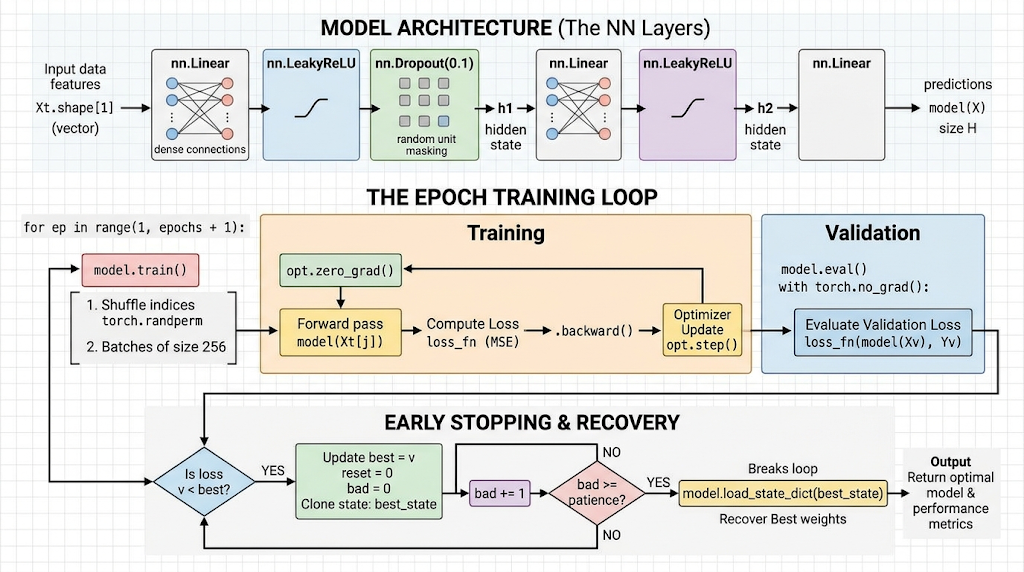
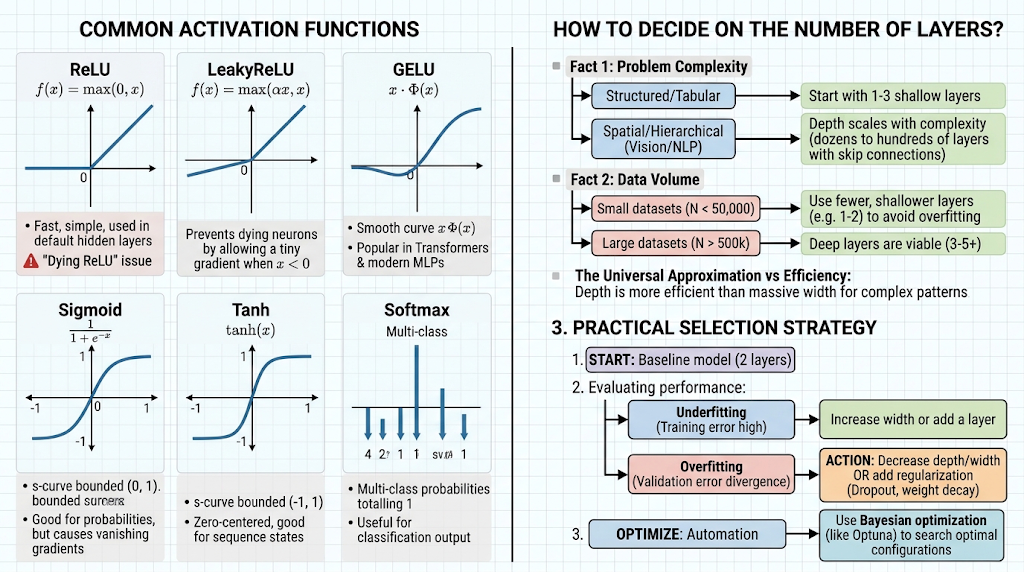

## 1. Setup & configuration

In [1]:
import os
import re
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from dotenv import load_dotenv
from entsoe import Area, EntsoePandasClient
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler

In [2]:
# ---- Data window & markets -------------------------------------------------------------------
START = pd.Timestamp("2026-06-01 12:00", tz="UTC")
END = pd.Timestamp("2026-11-02 23:00", tz="UTC")  # through 2026-11-03 00:00 CET

MARKETS = {            # name used in this notebook -> ENTSO-E code
    "DE_LU": "DE_LU",
    #"NL": "NL",
    #"DK1": "DK_1",
}

# ---- Model / pipeline configuration ----------------------------------------------------------
@dataclass(frozen=True)
class FeatureConfig:
    # Base lags. They are automatically pushed back (in whole weeks / days) when the forecast
    # horizon is longer than one day, so that no lag ever points at an unknown price.
    price_lag_hours: tuple = (48, 168)          # D-2 and D-7, same time of day
    actual_lag_hours: int = 48                  # realised actuals (generation) enter only as lags
    level_anchor_window_hours: int = 24         # rolling-mean window for the level anchor
    mandatory: tuple = ("known_level_at_gate", "residual_load", "sin_time", "cos_time")
    k: int = 8                                  # total number of selected features


@dataclass(frozen=True)
class SplitConfig:
    train_lookback_days: int = 15
    val_days: int = 7
    gate_closure_hour: int = 12


@dataclass(frozen=True)
class ForecastRequest:
    """What to forecast. Dates are local market time (Europe/Berlin for DE_LU).

    start / end : "2026-10-01" (whole day) or "2026-10-01 06:00" (from that hour on).
                  `end` is inclusive; a date-only `end` means "until the end of that day".
                  Leave `end` as None for a single day.
    hours       : optional hours of the day to keep, e.g. range(6, 22) or [7, 8, 17, 18].
                  None = all hours.
    """
    start: str
    end: str | None = None
    hours: tuple | None = None


@dataclass(frozen=True)
class ModelConfig:
    hidden: tuple = (64, 32)
    lr: float = 3e-4
    weight_decay: float = 1e-4
    epochs: int = 250
    patience: int = 30
    batch_size: int = 256
    seed: int = 42
    huber_beta: float = 1.0
    underpred_penalty: float = 1.6              # >1 punishes under-prediction (missed peaks) harder
    predict_delta: bool = False                 # model (price - known_level_at_gate) instead of price


@dataclass(frozen=True)
class PipelineConfig:
    target_col: str = "price"
    features: FeatureConfig = field(default_factory=FeatureConfig)
    split: SplitConfig = field(default_factory=SplitConfig)
    model: ModelConfig = field(default_factory=ModelConfig)


CFG = PipelineConfig()

## 2. Data: ENTSO-E download, cleaning, imputation

In [3]:
def list_entsoe_areas() -> None:
    """Print every ENTSO-E area code (handy for picking a market). Not called by default."""
    for area in Area:
        print(f"{area.name:<12} | {area.value:<20} | {area.meaning}")


def _normalize_name(name) -> str:
    """'Fossil Brown coal/Lignite' -> 'fossil_brown_coal_lignite'."""
    return re.sub(r"[^a-z0-9]+", "_", str(name).lower()).strip("_")


def _to_frame(obj) -> pd.DataFrame:
    """Series / DataFrame (possibly MultiIndex columns) -> DataFrame with flat, snake_case columns."""
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj.copy()
    if isinstance(df.columns, pd.MultiIndex):
        # entsoe-py returns (type, 'Actual Aggregated' | 'Actual Consumption'); keep production only
        is_agg = df.columns.get_level_values(-1) == "Actual Aggregated"
        if is_agg.any():
            df = df.loc[:, is_agg]
        df.columns = df.columns.get_level_values(0)
    df.columns = [_normalize_name(c) for c in df.columns]
    return df.loc[:, ~df.columns.duplicated()]


def _align(obj, index: pd.DatetimeIndex, *, prefix: str = "", name: str | None = None) -> pd.DataFrame:
    """Flatten `obj` and reindex it strictly onto the master (price) index without future leakage."""
    df = _to_frame(obj)
    if name is not None:                        
        df = df.iloc[:, [0]]
        df.columns = [name]
    else:
        df.columns = [f"{prefix}{c}" for c in df.columns]
    df = df[~df.index.duplicated()].sort_index()
    
    # Use exact reindexing or merge to avoid pulling future/nearest timestamps illegally
    return df.reindex(index)


def _impute(df: pd.DataFrame) -> pd.DataFrame:
    """Per-feature-type gap filling. The target (price) is never interpolated or back-filled."""
    df = df.copy()
    df["price"] = df["price"].ffill(limit=2)
    for col in df.columns.drop("price"):
        if "solar" in col:
            df[col] = df[col].fillna(0.0)
        else:
            df[col] = df[col].interpolate(method="linear", limit=4).ffill().bfill()
    return df.dropna(subset=["price"])


def fetch_entsoe_market_data(start: pd.Timestamp, end: pd.Timestamp, country_code: str) -> pd.DataFrame:
    """
    Download and merge, on the day-ahead price index:
      price           day-ahead price (target)
      load_forecast   day-ahead load forecast             (ex-ante)
      forecast_*      day-ahead wind & solar forecasts    (ex-ante)
      actual_load     realised load                       (only usable lagged)
      actual_*        realised generation by type         (only usable lagged)
    """
    load_dotenv()
    api_key = os.getenv("ENTSOE_API_KEY")
    if not api_key:
        raise ValueError("ENTSOE_API_KEY not found in the environment or .env file.")

    client = EntsoePandasClient(api_key=api_key)
    kw = dict(country_code=country_code, start=start, end=end)
    print(f"Fetching {country_code}: {start} -> {end}")

    prices = _to_frame(client.query_day_ahead_prices(**kw)).iloc[:, 0].rename("price")
    index = prices.index

    frames = [
        prices.to_frame(),
        _align(client.query_load_forecast(**kw), index, name="load_forecast"),
        _align(client.query_wind_and_solar_forecast(**kw), index, prefix="forecast_"),
        _align(client.query_load(**kw), index, name="actual_load"),
    ]
    try:
        frames.append(_align(client.query_generation(**kw), index, prefix="actual_"))
    except Exception as exc:  # generation is optional
        print(f"  warning: actual generation unavailable ({exc})")

    df = pd.concat(frames, axis=1)
    df = df.loc[:, ~df.columns.duplicated()].sort_index()
    df = _impute(df)
    print(f"  -> shape {df.shape}")
    return df

In [4]:
market_data = {name: fetch_entsoe_market_data(START, END, code) for name, code in MARKETS.items()}

for name, df in market_data.items():
    print(f"{name:<6} {df.index.min()} -> {df.index.max()}  tz={df.index.tz}  cols={df.shape[1]}")
market_data["DE_LU"].tail()


Fetching DE_LU: 2026-06-01 12:00:00+00:00 -> 2026-11-02 23:00:00+00:00
  -> shape (14829, 22)
DE_LU  2026-06-01 14:00:00+02:00 -> 2026-11-03 00:00:00+01:00  tz=Europe/Berlin  cols=22


,price,load_forecast,forecast_solar,forecast_wind_offshore,forecast_wind_onshore,actual_load,actual_biomass,actual_fossil_brown_coal_lignite,actual_fossil_coal_derived_gas,actual_fossil_gas,...,actual_geothermal,actual_hydro_pumped_storage,actual_hydro_run_of_river_and_pondage,actual_hydro_water_reservoir,actual_other_renewable,actual_solar,actual_waste,actual_wind_offshore,actual_wind_onshore,actual_other
2026-11-02 23:00:00+01:00,235.79,52022.768759,0.0,5307.94,6434.67156,54085.44610,4118.82243,10589.65326,274.88700,12976.61143,...,19.0,640.7299,1018.83176,250.6667,78.108,0.036,843.9271,4860.532,5651.89605,224.07182
2026-11-02 23:15:00+01:00,232.49,51257.414495,0.0,5261.25,6423.53482,53710.97036,4115.75643,10384.34201,274.44133,12750.66179,...,19.0,299.2463,1029.93546,174.7251,78.108,0.031,841.4818,4906.890,5596.15902,224.06782
2026-11-02 23:30:00+01:00,227.07,50544.828406,0.0,5221.58,6414.58642,52729.97243,4101.51753,10401.99569,272.80933,12647.53993,...,19.0,145.6250,1034.63497,74.9999,78.108,0.028,838.0679,4971.872,5635.95217,224.04682
2026-11-02 23:45:00+01:00,218.62,50009.813063,0.0,5176.11,6404.87474,52506.96669,4085.81343,10366.97039,265.95533,12575.57669,...,19.0,72.9450,1038.19817,33.2743,78.108,0.022,840.0286,4850.708,5620.40343,224.24782
2026-11-03 00:00:00+01:00,222.50,50009.813063,0.0,5176.11,6404.87474,52506.96669,4085.81343,10366.97039,265.95533,12575.57669,...,19.0,72.9450,1038.19817,33.2743,78.108,0.000,840.0286,4850.708,5620.40343,224.24782


## 3. Features (leakage-free)

* **Price lags** (D-2, D-7), **rolling level anchor** (24h mean). Lags are pushed back automatically for multi-day\n  forecasts so no lag ever points at a price that is unknown at gate closure.
* **Residual load** = day-ahead load forecast minus day-ahead wind + solar forecast.
* **Realised generation** (`actual_*`) enters only as a lag, since it is not known for day D at gate closure.
* **Calendar**: sine/cosine of time of day and day of week.

Lags are time-based (`shift(freq=...)`), so gaps in the index don't silently shift rows.

In [130]:
def _lag(series: pd.Series, hours: float) -> pd.Series:
    """Value observed `hours` earlier, aligned back onto the original index (gap-safe)."""
    return series.shift(freq=pd.Timedelta(hours=hours)).reindex(series.index)


def _round_up(x: float, step: int) -> int:
    return int(-(-x // step) * step)


def safe_lags(cfg: PipelineConfig, horizon_days: int) -> dict:
    """
    Smallest lags that are still known at the gate closure (D-1 12:00) for EVERY hour of a
    `horizon_days`-day forecast window.

    * Day-ahead prices are known up to the end of D-1, so for the last day of the window
      (D+H-1) a price lag must be >= 24*H hours.
    * Realised generation is only known up to ~D-1 12:00 -> lag >= 24*H + 12 hours.
    * Level anchor (rolling mean ending at t-lag): lag >= 24*H.
    Lags are rounded up to whole days (same time of day), price lags to whole weeks when the
    configured lag was a weekly one (keeps the weekday pattern).
    """
    fc, H = cfg.features, max(1, int(horizon_days))
    price = []
    for h in fc.price_lag_hours:
        step = 168 if h % 168 == 0 else 24
        price.append(max(h, _round_up(24 * H, step)))
    return {
        "price": sorted(set(price)),
        "actual": max(fc.actual_lag_hours, _round_up(24 * H + 12, 24)),
        "anchor": 24 * H,
    }


def build_features(df: pd.DataFrame, cfg: PipelineConfig = CFG, horizon_days: int = 1) -> pd.DataFrame:
    fc, target = cfg.features, cfg.target_col
    lags = safe_lags(cfg, horizon_days)
    df = df.sort_index()
    out = pd.DataFrame(index=df.index)

    # Target
    out[target] = df[target]

    # 1. Price lags (gate-safe for the whole forecast window)
    for h in lags["price"]:
        out[f"price_lag_{h}h"] = _lag(df[target], h)

    # 2. Level anchor: 24h rolling mean of prices, shifted so it ends before the gate
    window = f"{fc.level_anchor_window_hours}h"
    rolling_mean = df[target].rolling(window).mean()
    out["known_level_at_gate"] = _lag(rolling_mean, lags["anchor"])

    # 3. Fundamental ex-ante driver: net residual load
    ren_cols = [c for c in df.columns if c.startswith("forecast_") and ("wind" in c or "solar" in c)]
    if "load_forecast" in df.columns:
        ren_total = df[ren_cols].sum(axis=1) if ren_cols else 0.0
        out["residual_load"] = df["load_forecast"] - ren_total
        out["renewable_ratio"] = ren_total / df["load_forecast"].replace(0, np.nan)

    # 4. ADDED: Smoothed load-to-wind ratio feature with a safe denominator buffer and 24h diff
    if "actual_load" in df.columns and "forecast_wind_onshore" in df.columns:
        net_ratio = df["actual_load"] / (df["forecast_wind_onshore"] + 10.0)
        out["load_wind_ratio_diff24"] = net_ratio.diff(24)

    # 5. System generation state (aggregate thermal generation, lagged)
    fossil_cols = [c for c in df.columns if c.startswith("actual_") and "fossil" in c]
    if fossil_cols:
        out[f"thermal_gen_lag_{lags['actual']}h"] = _lag(df[fossil_cols].sum(axis=1), lags['actual'])

    # 6. Calendar & seasonality
    minute_of_day = out.index.hour * 60 + out.index.minute
    out["sin_time"] = np.sin(2 * np.pi * minute_of_day / 1440.0)
    out["cos_time"] = np.cos(2 * np.pi * minute_of_day / 1440.0)
    out["sin_dow"] = np.sin(2 * np.pi * out.index.dayofweek / 7.0)
    out["cos_dow"] = np.cos(2 * np.pi * out.index.dayofweek / 7.0)
    doy = out.index.dayofyear
    out["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    out["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)

    inputs = [c for c in out.columns if c != target]
    return out.dropna(subset=inputs)


## 4. Data preparation: gate-closure split, feature selection, scaling

In [ ]:
@dataclass
class ForecastData:
    X_train: np.ndarray
    y_train: np.ndarray
    X_val: np.ndarray
    y_val: np.ndarray
    X_test: np.ndarray
    y_test: np.ndarray | None
    test_index: pd.DatetimeIndex
    features: list
    scaler_y: StandardScaler
    anchor_test: np.ndarray | None = None       # added back to predictions when predict_delta=True


def select_features(train_df: pd.DataFrame, cfg: PipelineConfig = CFG) -> list:
    """Mandatory features first; remaining slots filled by mutual information (train data only)."""
    target, fc = cfg.target_col, cfg.features
    guaranteed = [f for f in fc.mandatory if f in train_df.columns]
    missing = set(fc.mandatory) - set(guaranteed)
    if missing:
        print(f"Warning: mandatory features not found and skipped: {sorted(missing)}")

    drop = set(guaranteed) | {target, "target_delta"}
    candidates = [c for c in train_df.columns if c not in drop]
    slots = fc.k - len(guaranteed)
    extra = []
    if slots > 0 and candidates:
        mi = mutual_info_regression(train_df[candidates].values, train_df[target].values, random_state=42)
        extra = pd.Series(mi, index=candidates).nlargest(slots).index.tolist()

    selected = guaranteed + extra
    print(f"Selected {len(selected)} features: {selected}\n")
    return selected


def _localize(ts, tz):
    ts = pd.Timestamp(ts)
    if tz is None:
        return ts
    return ts.tz_localize(tz) if ts.tz is None else ts.tz_convert(tz)


def resolve_window(req: ForecastRequest, tz) -> tuple:
    """-> (first_day_start, window_start, window_end_exclusive, horizon_days)."""
    start = _localize(req.start, tz)
    end_raw = req.end if req.end is not None else req.start
    end = _localize(end_raw, tz)
    date_only_end = isinstance(end_raw, str) and len(end_raw.strip()) <= 10
    day_start = start.normalize()
    window_start = start
    window_end = end.normalize() + pd.DateOffset(days=1) if date_only_end else end + pd.Timedelta(minutes=1)
    if window_end <= window_start:
        raise ValueError("Forecast end must be after forecast start.")
    horizon_days = int(np.ceil((window_end.normalize() + (pd.Timedelta(0) if window_end == window_end.normalize()
                                                          else pd.Timedelta(days=1)) - day_start) / pd.Timedelta(days=1)))
    return day_start, window_start, window_end, max(1, horizon_days)


In [145]:
from sklearn.preprocessing import RobustScaler # Make sure RobustScaler is imported

def prepare_data(df: pd.DataFrame, req: ForecastRequest, cfg: PipelineConfig = CFG) -> ForecastData:
    sp, target = cfg.split, cfg.target_col
    df = df.sort_index()
    tz = df.index.tz
    day_start, win_start, win_end, _ = resolve_window(req, tz)
    
    val_end = day_start - pd.DateOffset(days=1)
    val_start = val_end - pd.DateOffset(days=sp.val_days)
    train_start = val_start - pd.DateOffset(days=sp.train_lookback_days)

    idx = df.index
    train_df = df[(idx >= train_start) & (idx < val_start)].dropna(subset=[target])
    val_df = df[(idx >= val_start) & (idx < val_end)].dropna(subset=[target])
    test_df = df[(idx >= win_start) & (idx < win_end)]
    if req.hours is not None:
        test_df = test_df[test_df.index.hour.isin(list(req.hours))]

    features = select_features(train_df, cfg)

    delta = cfg.model.predict_delta
    def tgt(part):
        y = part[target].values.reshape(-1, 1)
        return y - part[["known_level_at_gate"]].values if delta else y

    scaler_x = StandardScaler().fit(train_df[features].values)
    
    # USE RobustScaler for y to stabilize gradients without crushing upper tails
    scaler_y = RobustScaler().fit(tgt(train_df))

    y_test = test_df[[target]].values if target in test_df.columns else None
    return ForecastData(
        X_train=scaler_x.transform(train_df[features].values),
        y_train=scaler_y.transform(tgt(train_df)),
        X_val=scaler_x.transform(val_df[features].values),
        y_val=scaler_y.transform(tgt(val_df)),
        X_test=scaler_x.transform(test_df[features].values),
        y_test=y_test,
        test_index=test_df.index,
        features=features,
        scaler_y=scaler_y,
        anchor_test=test_df[["known_level_at_gate"]].values.ravel() if delta else None,
    )

## 5. Model: MLP, asymmetric Huber loss, training

In [149]:
import torch
import torch.nn as nn

class ForecastMLP(nn.Module):
    def __init__(self, in_features: int, hidden: tuple = (64, 32), out_features: int = 1, dropout: float = 0.1):
        super().__init__()
        layers = []
        prev = in_features
        for h in hidden:
            layers.extend([
                nn.Linear(prev, h),
                nn.LayerNorm(h),       # Stabilizes training across volatile energy features
                nn.GELU(),             # Smooth non-linear activation
                nn.Dropout(dropout)    # Prevents overfitting to noise
            ])
            prev = h
        layers.append(nn.Linear(prev, out_features))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class AsymmetricHuberLoss(nn.Module):
    """Aggressive Huber loss that heavily weights under-predictions to capture power market spikes."""

    def __init__(self, beta: float = 1.0, underpred_penalty: float = 4.0, extreme_penalty: float = 10.0):
        super().__init__()
        self.beta = beta
        self.penalty = underpred_penalty
        self.extreme_penalty = extreme_penalty

    def forward(self, pred, target):
        diff = target - pred
        abs_diff = diff.abs()
        
        # Standard Huber loss inner calculation
        huber = torch.where(abs_diff < self.beta,
                            0.5 * diff ** 2,
                            self.beta * (abs_diff - 0.5 * self.beta))
        
        # Base weight: heavier penalty for any under-prediction (target > pred)
        weights = torch.where(diff > 0,
                              torch.full_like(diff, self.penalty),
                              torch.ones_like(diff))
        
        # Extra tier: If the target value is very high (e.g., top standardized tail or raw high price), 
        # apply an even harsher penalty for missing it. 
        # Note: Since targets are standardized (StandardScaler), high values are > 1.5 or 2.0 standard deviations.
        extreme_mask = (target > 1.5) & (diff > 0)
        weights = torch.where(extreme_mask, torch.full_like(diff, self.extreme_penalty), weights)

        return (weights * huber).mean()


def _tensor(a: np.ndarray) -> torch.Tensor:
    return torch.as_tensor(a, dtype=torch.float32)


def fit_model(data: ForecastData, cfg: ModelConfig = CFG.model) -> ForecastMLP:
    torch.manual_seed(cfg.seed)
    Xt, Yt, Xv, Yv = map(_tensor, (data.X_train, data.y_train, data.X_val, data.y_val))

    model = ForecastMLP(Xt.shape[1], cfg.hidden, Yt.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    loss_fn = AsymmetricHuberLoss(cfg.huber_beta, cfg.underpred_penalty)

    best_loss, best_state, stale = float("inf"), None, 0
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(perm), cfg.batch_size):
            batch = perm[i:i + cfg.batch_size] 
            optimizer.zero_grad()
            loss_fn(model(Xt[batch]), Yt[batch]).backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), Yv).item()

        if val_loss < best_loss:
            best_loss, stale = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg.patience:
                print(f"Early stopping at epoch {epoch}. Best validation loss: {best_loss:.4f}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model.eval()


@torch.no_grad()
def predict(model: ForecastMLP, X: np.ndarray, scaler_y = None) -> np.ndarray:
    model.eval()
    preds = model(_tensor(X)).numpy().ravel()
    if scaler_y is not None:
        preds = scaler_y.inverse_transform(preds.reshape(-1, 1)).ravel()
    return preds

## 6. Pipeline & evaluation

In [150]:
def evaluate_forecast(forecast_df: pd.DataFrame) -> dict:
    """RMSE / MAE in EUR/MWh over the steps that have actuals (empty dict if none)."""
    if "Actual" not in forecast_df.columns:
        return {}
    both = forecast_df[["Forecast", "Actual"]].dropna()
    if both.empty:
        return {}
    err = both["Forecast"] - both["Actual"]
    return {"rmse": float(np.sqrt((err ** 2).mean())), "mae": float(err.abs().mean())}


def run_forecast_pipeline(df: pd.DataFrame, req: ForecastRequest, cfg: PipelineConfig = CFG) -> pd.DataFrame:
    """Full run: features -> split/selection/scaling -> train -> forecast the requested window."""
    if not isinstance(req, ForecastRequest):             # allow a plain "2026-10-01" string
        req = ForecastRequest(str(req))
    _, _, _, horizon_days = resolve_window(req, df.index.tz)
    print(f"Horizon: {horizon_days} day(s) -> lags {safe_lags(cfg, horizon_days)}")

    featured = build_features(df, cfg, horizon_days)
    fdata = prepare_data(featured, req, cfg)
    model = fit_model(fdata, cfg.model)
    preds = predict(model, fdata.X_test)
    if fdata.anchor_test is not None:
        preds = preds + fdata.anchor_test

    out = {"Forecast": np.round(preds, 2)}
    if fdata.y_test is not None and not np.isnan(fdata.y_test).all():
        actual = fdata.y_test.ravel()
        out["Actual"] = np.round(actual, 2)
        out["error"] = np.round(preds - actual, 2)
    result = pd.DataFrame(out, index=fdata.test_index)

    metrics = evaluate_forecast(result)
    if metrics:
        print(f"RMSE {metrics['rmse']:.2f} | MAE {metrics['mae']:.2f} EUR/MWh")
    return result


def plot_forecast(result: pd.DataFrame, title: str = "") -> None:
    fig, ax = plt.subplots(figsize=(10, 3.4))
    # draw on a regular grid so hours that were not selected show as gaps, not straight lines
    if len(result) > 2:
        step = result.index.to_series().diff().min()
        grid = result.reindex(pd.date_range(result.index[0], result.index[-1], freq=step))
    else:
        grid = result
    if "Actual" in grid:
        ax.plot(grid.index, grid["Actual"], color="black", linestyle="--", label="Actual")
    ax.plot(grid.index, grid["Forecast"], label="Forecast")
    ax.set(title=title, ylabel="EUR/MWh", xlabel="")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## 7. Run forecasts

Pick the market, the days and (optionally) the hours. Run the **selector** cell below for dropdowns/date pickers,
or just edit the plain `REQUESTS` cell. Dates and hours are local market time.

In [12]:
pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


c:\PythonEnvs\PyPSA\.venv\Scripts\python.exe: No module named pip


In [71]:
# ---- Interactive selector (needs `pip install ipywidgets`; falls back to REQUESTS below) -------------
try:
    import ipywidgets as w
    from IPython.display import display

    _default = (next(iter(market_data.values())).index.max() - pd.Timedelta(days=1)).date()

    w_market = w.Dropdown(options=list(market_data), description="Market")
    w_start = w.DatePicker(value=_default, description="From day")
    w_end = w.DatePicker(value=_default, description="To day")
    w_hours = w.IntRangeSlider(value=[0, 23], min=0, max=23, step=1, description="Hours",
                               continuous_update=False, layout=w.Layout(width="420px"))
    w_all = w.Checkbox(value=True, description="All hours of the day")
    w_run = w.Button(description="Run forecast", button_style="primary")
    w_out = w.Output()

    def _on_run(_):
        w_out.clear_output()
        with w_out:
            hours = None if w_all.value else tuple(range(w_hours.value[0], w_hours.value[1] + 1))
            req = ForecastRequest(str(w_start.value), str(w_end.value), hours)
            res = run_forecast_pipeline(market_data[w_market.value], req, CFG)
            results[w_market.value] = res
            plot_forecast(res, f"{w_market.value} day-ahead price, {w_start.value} to {w_end.value}")
            display(res)

    results = {}
    w_run.on_click(_on_run)
    display(w.VBox([w_market, w.HBox([w_start, w_end]), w_all, w_hours, w_run, w_out]))
except ImportError:
    print("ipywidgets not installed - use the REQUESTS cell below instead.")


ipywidgets not installed - use the REQUESTS cell below instead.


In [115]:
market_data[market].head()

,price,load_forecast,forecast_solar,forecast_wind_offshore,forecast_wind_onshore,actual_load,actual_biomass,actual_fossil_brown_coal_lignite,actual_fossil_coal_derived_gas,actual_fossil_gas,...,actual_geothermal,actual_hydro_pumped_storage,actual_hydro_run_of_river_and_pondage,actual_hydro_water_reservoir,actual_other_renewable,actual_solar,actual_waste,actual_wind_offshore,actual_wind_onshore,actual_other
2026-06-01 14:00:00+02:00,86.35,59274.821724,42085.48978,385.00,3086.73464,55749.37313,3096.901768,4117.78741,329.58167,2366.27643,...,19.969,6.1060,1630.71002,20.8728,81.259488,46150.150684,666.0781,544.732,2478.798940,134.73963
2026-06-01 14:15:00+02:00,86.95,58919.839825,41664.36650,379.58,3079.30792,55192.26108,3105.579212,4072.65402,318.04067,2376.77740,...,19.912,6.1677,1626.92182,20.3054,80.798516,45622.341040,662.8932,545.033,2531.204300,134.73963
2026-06-01 14:30:00+02:00,86.61,58474.539674,41126.92699,380.26,3054.64357,54878.19102,3121.209380,4087.34909,326.19801,2366.93430,...,19.984,6.1645,1602.53262,20.3649,80.938272,45042.480880,657.0652,533.005,2529.321364,134.73963
2026-06-01 14:45:00+02:00,89.88,58367.190556,40385.32624,381.08,3019.47137,55201.54442,3126.280868,4141.86165,320.48301,2422.51833,...,19.622,6.2125,1613.05792,27.2550,82.032928,44396.331244,657.7025,502.810,2595.121428,134.73963
2026-06-01 15:00:00+02:00,86.00,58381.011066,39424.23942,380.10,2975.96749,55019.82537,3128.376952,4167.20973,317.67866,2473.09000,...,19.432,6.1337,1656.77352,25.6820,82.698560,43701.574484,659.7897,424.798,2520.522024,134.73963


<Axes: >

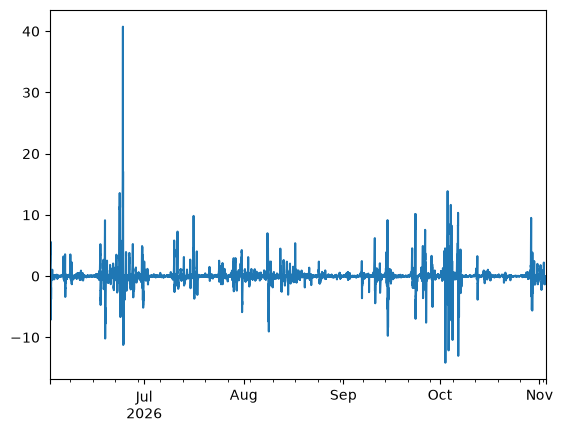

In [129]:
#(market_data[market]["price"]).plot()
(market_data[market]["actual_load"]/market_data[market]["forecast_wind_onshore"]*1.1).diff().plot()

<Axes: >

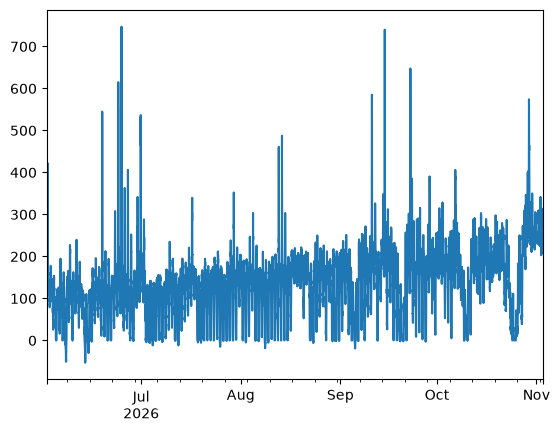

In [124]:
(market_data[market]["price"]).plot()


===== DE_LU =====
Horizon: 4 day(s) -> lags {'price': [96, 168], 'actual': 120, 'anchor': 96}
Selected 8 features: ['known_level_at_gate', 'residual_load', 'sin_time', 'cos_time', 'renewable_ratio', 'cos_doy', 'sin_doy', 'thermal_gen_lag_120h']

Early stopping at epoch 56. Best validation loss: 0.4248
RMSE 277.00 | MAE 270.03 EUR/MWh


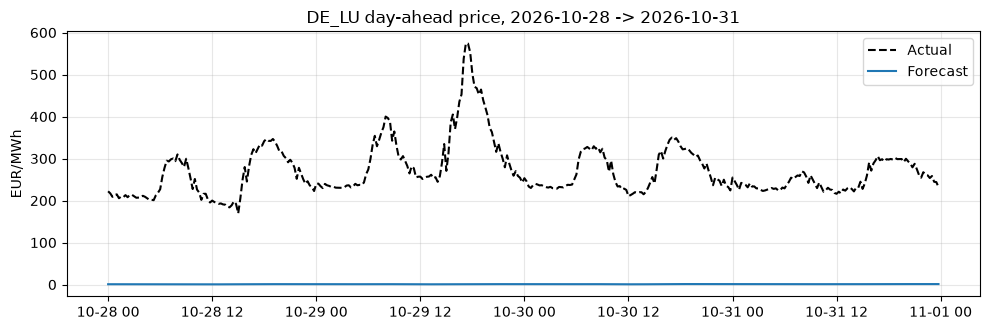

In [151]:
# ---- Plain (non-widget) run: edit and execute ------------------------------------------------------
REQUESTS = {
    # market: ForecastRequest(start, end=None, hours=None)
    "DE_LU": ForecastRequest("2026-10-28", "2026-10-31"),                            # 4 full days
    # "DE_LU": ForecastRequest("2026-10-01"),                                         # single day
    # "DE_LU": ForecastRequest("2026-10-01 06:00", "2026-10-02 18:00"),               # exact start/end hour
    # "DE_LU": ForecastRequest("2026-10-01", "2026-10-04", hours=range(7, 21)),       # only 07:00-20:59 each day
    # "NL":    ForecastRequest("2026-10-11"),
}

results = {}
for market, req in REQUESTS.items():
    print(f"\n===== {market} =====")
    results[market] = run_forecast_pipeline(market_data[market], req, CFG)
    plot_forecast(results[market], f"{market} day-ahead price, {req.start} -> {req.end or req.start}")
